# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 600                       # used by the bootstrap later; recorded in decisions.md when it matters
rng = np.random.default_rng(SEED)

RAW = Path("data/raw")
FIG = Path("fig")
FIG.mkdir(exist_ok=True)

# The files this notebook reads, with the SHA-256 from data/README.md.
# 2021 is not read (decisions.md, 2026-11-06).
FILES = {
    2022: ("NSDUH-2022-DS0001-bndl-data-tsv_v2.zip", "cde54c4af548de3cacebff00127fda4ffa645fb9cd4803dbd0ae9ed3df1c799f"),
    2023: ("nsduh-2023-ds0001-bndl-data-tsv_v2.zip", "f2ed2fb234ebe04b6548e827fd90138830bb6bc8411e215a526d0ef3ddcd9324"),
    2024: ("NSDUH-2024-DS0001-bndl-data-tsv_v1.zip", "a26f3009991e848c9a6b594e5d57906621a75459c7ba51d10b409ed2f8432a8f"),
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for year, (name, expected) in FILES.items():
    got = sha256(RAW / name)
    assert got == expected, f"{name}: SHA-256 {got} does not match data/README.md"
print(f"{len(FILES)} files match the SHA-256 in data/README.md")


3 files match the SHA-256 in data/README.md


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


,adults,in treatment,share in treatment (wtd),"at risk, n","at risk, rate (wtd)",role
2022,47100,11978,21.5%,2014,13.4%,train
2023,45133,11851,23.1%,1938,12.7%,test
2024,47299,12444,23.0%,1814,11.9%,check (new wording)


n by year,2022,2023,2024
age,,,
18-25,3914,3689,3753
26-34,2610,2591,2806
35-49,3423,3539,3733
50-64,1187,1157,1237
65+,844,875,915


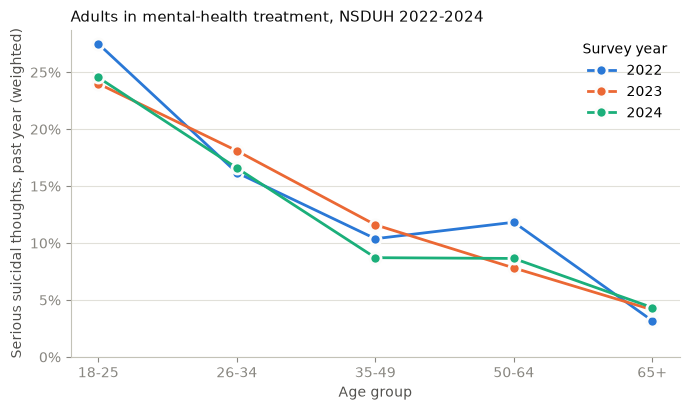

In [2]:
# "In treatment" is MHTRTPY in 2022-2023 and MHTRTPY2 in 2024; SAMHSA says 2024 is not comparable.
TRT = {2022: "MHTRTPY", 2023: "MHTRTPY", 2024: "MHTRTPY2"}
COLS = ["QUESTID2", "CATAG6", "IRSUICTHNK", "ANALWT2_C", "VESTR_C", "VEREP"]
AGE = {2: "18-25", 3: "26-34", 4: "35-49", 5: "50-64", 6: "65+"}

def load(year):
    """Read one year's TSV straight from its zip, without unzipping."""
    with zipfile.ZipFile(RAW / FILES[year][0]) as zf:
        (name,) = zf.namelist()          # each zip holds exactly one file
        with zf.open(name) as fh:
            d = pd.read_csv(fh, sep="\t", usecols=COLS + [TRT[year]])
    return d.rename(columns={TRT[year]: "in_trt"}).assign(year=year)

everyone = pd.concat([load(y) for y in FILES], ignore_index=True)
adults = everyone[everyone.CATAG6 >= 2]
df = adults[adults.in_trt == 1].copy()          # the population: adults in MH treatment, past year
df["at_risk"] = df.IRSUICTHNK.astype(int)       # serious suicidal thoughts, past year (imputation-revised)
df["age"] = pd.Categorical(df.CATAG6.map(AGE), categories=list(AGE.values()), ordered=True)
assert df.at_risk.isin([0, 1]).all()

def wmean(x, w):
    return (x * w).sum() / w.sum()

summary = pd.DataFrame({
    "adults": adults.groupby("year").size(),
    "in treatment": df.groupby("year").size(),
    "share in treatment (wtd)": adults.groupby("year").apply(lambda g: wmean(g.in_trt == 1, g.ANALWT2_C)),
    "at risk, n": df.groupby("year").at_risk.sum(),
    "at risk, rate (wtd)": df.groupby("year").apply(lambda g: wmean(g.at_risk, g.ANALWT2_C)),
    "role": pd.Series({2022: "train", 2023: "test", 2024: "check (new wording)"}),
})
pct = ["share in treatment (wtd)", "at risk, rate (wtd)"]
display(summary.assign(**{k: summary[k].map("{:.1%}".format) for k in pct}))

by_age = (df.groupby(["year", "age"], observed=True)
            .apply(lambda g: pd.Series({"n": len(g), "rate": wmean(g.at_risk, g.ANALWT2_C)}))
            .reset_index())
display(by_age.pivot(index="age", columns="year", values="n").astype(int).rename_axis(columns="n by year"))

# Raw-data plot: weighted rate of serious suicidal thoughts by age group, one line per year.
COLORS = {2022: "#2a78d6", 2023: "#eb6834", 2024: "#1baf7a"}   # categorical slots 1-3, fixed order
fig, ax = plt.subplots(figsize=(7, 4.2))
for year, g in by_age.groupby("year"):
    ax.plot(g.age.astype(str), g.rate, color=COLORS[year], lw=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=str(year))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Age group", color="#52514e")
ax.set_ylabel("Serious suicidal thoughts, past year (weighted)", color="#52514e")
ax.set_title("Adults in mental-health treatment, NSDUH 2022-2024", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, title="Survey year", loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "raw_rate_by_age.png", dpi=150)
plt.show()


## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
